# Loss Visualization from TensorBoard

This notebook loads training losses from the latest TensorBoard run and visualizes:
1. Raw losses for streams A and B with smoothed versions
2. EMA losses for streams A and B (raw only)


In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from tensorboard.backend.event_processing import event_accumulator
from pathlib import Path

import pandas as pd

# Set plot style
plt.style.use('default')
plt.rcParams['figure.figsize'] = (14, 6)
plt.rcParams['font.size'] = 10


## Load TensorBoard Data


In [2]:
def get_latest_run(tensorboard_dir='./tensorboard_logs'):
    """Find the latest run directory in tensorboard logs."""
    runs = [d for d in Path(tensorboard_dir).iterdir() if d.is_dir()]
    if not runs:
        raise ValueError(f"No runs found in {tensorboard_dir}")
    latest_run = max(runs, key=lambda x: x.stat().st_mtime)
    return latest_run

def load_tensorboard_scalars(log_dir, tags):
    """Load scalar data from TensorBoard event files."""
    ea = event_accumulator.EventAccumulator(str(log_dir))
    ea.Reload()
    
    data = {}
    for tag in tags:
        if tag in ea.Tags()['scalars']:
            events = ea.Scalars(tag)
            steps = [e.step for e in events]
            values = [e.value for e in events]
            data[tag] = {'steps': np.array(steps), 'values': np.array(values)}
        else:
            print(f"Warning: Tag '{tag}' not found in logs")
    
    return data

def smooth_values(values, window=50):
    """Apply moving average smoothing to values."""
    if len(values) < window:
        window = max(1, len(values) // 2)
    
    smoothed = np.convolve(values, np.ones(window) / window, mode='valid')
    # Pad to match original length
    pad_left = (len(values) - len(smoothed)) // 2
    pad_right = len(values) - len(smoothed) - pad_left
    smoothed = np.pad(smoothed, (pad_left, pad_right), mode='edge')
    
    return smoothed


## Latest Run: All Metrics Visualization


Loading data from: tensorboard_logs/run_20251013_014943

Loaded 5 metrics:
  train/loss_A: 10000 data points
  train/loss_B: 10000 data points
  train/loss_total: 10000 data points
  train/ema_loss_A: 10000 data points
  train/ema_loss_B: 10000 data points
Last step: 88870
Alpha range: [0.9474, 1.0833]
Beta range: [0.9167, 1.0526]
Final alpha: 1.0302
Final beta: 0.9698


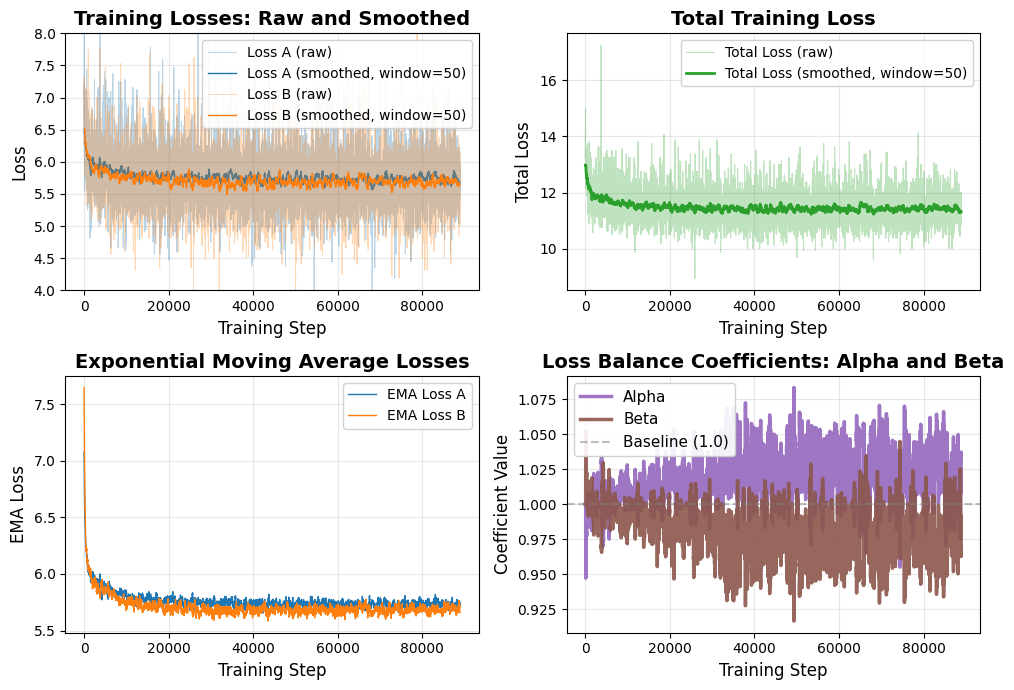

In [4]:
# Find and load data from the latest run
latest_run = get_latest_run()
print(f"Loading data from: {latest_run}")



# Define tags to load
tags = ['train/loss_A', 'train/loss_B', 'train/loss_total', 'train/ema_loss_A', 'train/ema_loss_B']

# Load data
data = load_tensorboard_scalars(latest_run, tags)

print(f"\nLoaded {len(data)} metrics:")
for tag, values in data.items():
    print(f"  {tag}: {len(values['steps'])} data points")
print(f"Last step: {values['steps'][-1]}")


# Set smoothing window size
smoothing_window = 50

# Load alpha and beta data from the latest run
alpha_beta_tags = ['loss_balance/alpha', 'loss_balance/beta']
alpha_beta_data = load_tensorboard_scalars(latest_run, alpha_beta_tags)

# Create figure with four subplots (2x2 grid)
fig, axes = plt.subplots(2, 2, figsize=(10, 7))

# Colors for streams A and B
color_A = '#1f77b4'  # Blue
color_B = '#ff7f0e'  # Orange
color_total = '#2ca02c'  # Green
color_alpha = '#9467bd'  # Purple
color_beta = '#8c564b'   # Brown

# Plot 1: Loss A and B (top-left)
ax1 = axes[0, 0]
if 'train/loss_A' in data:
    steps_A = data['train/loss_A']['steps']
    values_A = data['train/loss_A']['values']
    smoothed_A = smooth_values(values_A, window=smoothing_window)
    
    # Raw (pale)
    ax1.plot(steps_A, values_A, color=color_A, alpha=0.3, linewidth=0.7, label='Loss A (raw)')
    # Smoothed (bright)
    ax1.plot(steps_A, smoothed_A, color=color_A, alpha=1.0, linewidth=1.0, label=f'Loss A (smoothed, window={smoothing_window})')

if 'train/loss_B' in data:
    steps_B = data['train/loss_B']['steps']
    values_B = data['train/loss_B']['values']
    smoothed_B = smooth_values(values_B, window=smoothing_window)
    
    # Raw (pale)
    ax1.plot(steps_B, values_B, color=color_B, alpha=0.3, linewidth=0.7, label='Loss B (raw)')
    # Smoothed (bright)
    ax1.plot(steps_B, smoothed_B, color=color_B, alpha=1.0, linewidth=1.0, label=f'Loss B (smoothed, window={smoothing_window})')

ax1.set_ylim(4, 8)
ax1.set_xlabel('Training Step', fontsize=12)
ax1.set_ylabel('Loss', fontsize=12)
ax1.set_title('Training Losses: Raw and Smoothed', fontsize=14, fontweight='bold')
ax1.legend(loc='best', framealpha=0.9)
ax1.grid(True, alpha=0.3)

# Plot 2: Total loss (top-right)
ax2 = axes[0, 1]
if 'train/loss_total' in data:
    steps_total = data['train/loss_total']['steps']
    values_total = data['train/loss_total']['values']
    smoothed_total = smooth_values(values_total, window=smoothing_window)
    
    # Raw (pale)
    ax2.plot(steps_total, values_total, color=color_total, alpha=0.3, linewidth=0.8, label='Total Loss (raw)')
    # Smoothed (bright)
    ax2.plot(steps_total, smoothed_total, color=color_total, alpha=1.0, linewidth=2.0, label=f'Total Loss (smoothed, window={smoothing_window})')

ax2.set_xlabel('Training Step', fontsize=12)
ax2.set_ylabel('Total Loss', fontsize=12)
ax2.set_title('Total Training Loss', fontsize=14, fontweight='bold')
ax2.legend(loc='best', framealpha=0.9)
ax2.grid(True, alpha=0.3)

# Plot 3: EMA losses (bottom-left)
ax3 = axes[1, 0]
if 'train/ema_loss_A' in data:
    steps_ema_A = data['train/ema_loss_A']['steps']
    values_ema_A = data['train/ema_loss_A']['values']
    ax3.plot(steps_ema_A, values_ema_A, color=color_A, linewidth=1.0, label='EMA Loss A')

if 'train/ema_loss_B' in data:
    steps_ema_B = data['train/ema_loss_B']['steps']
    values_ema_B = data['train/ema_loss_B']['values']
    ax3.plot(steps_ema_B, values_ema_B, color=color_B, linewidth=1.0, label='EMA Loss B')

ax3.set_xlabel('Training Step', fontsize=12)
ax3.set_ylabel('EMA Loss', fontsize=12)
ax3.set_title('Exponential Moving Average Losses', fontsize=14, fontweight='bold')
ax3.legend(loc='best', framealpha=0.9)
ax3.grid(True, alpha=0.3)

# Plot 4: Alpha and Beta coefficients (bottom-right)
ax4 = axes[1, 1]
if 'loss_balance/alpha' in alpha_beta_data and 'loss_balance/beta' in alpha_beta_data:
    # Plot Alpha
    steps_alpha = alpha_beta_data['loss_balance/alpha']['steps']
    values_alpha = alpha_beta_data['loss_balance/alpha']['values']
    ax4.plot(steps_alpha, values_alpha, color=color_alpha, linewidth=2.5, label='Alpha', alpha=0.9)
    
    # Plot Beta
    steps_beta = alpha_beta_data['loss_balance/beta']['steps']
    values_beta = alpha_beta_data['loss_balance/beta']['values']
    ax4.plot(steps_beta, values_beta, color=color_beta, linewidth=2.5, label='Beta', alpha=0.9)
    
    # Add baseline line at 1.0
    ax4.axhline(y=1.0, color='gray', linestyle='--', linewidth=1.5, alpha=0.5, label='Baseline (1.0)')
    
    print(f"Alpha range: [{values_alpha.min():.4f}, {values_alpha.max():.4f}]")
    print(f"Beta range: [{values_beta.min():.4f}, {values_beta.max():.4f}]")
    print(f"Final alpha: {values_alpha[-1]:.4f}")
    print(f"Final beta: {values_beta[-1]:.4f}")
else:
    print("Warning: Alpha and Beta data not found in the latest run")

ax4.set_xlabel('Training Step', fontsize=12)
ax4.set_ylabel('Coefficient Value', fontsize=12)
ax4.set_title('Loss Balance Coefficients: Alpha and Beta', fontsize=14, fontweight='bold')
ax4.legend(loc='best', framealpha=0.9, fontsize=11)
ax4.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


In [4]:
step_interval = 200


if 'loss_balance/alpha' in alpha_beta_data and 'loss_balance/beta' in alpha_beta_data:
    steps_alpha = alpha_beta_data['loss_balance/alpha']['steps']

    values_alpha = alpha_beta_data['loss_balance/alpha']['values']
    values_beta = alpha_beta_data['loss_balance/beta']['values']
    
    print(f"\nAlpha and Beta values for some steps:")
    print("Step".rjust(10) + "Alpha".rjust(12) + "Beta".rjust(12))
    print("-" * 34)
    
    for i, step in enumerate(steps_alpha):
        if step % step_interval == 0:
            print(f"{int(step):10d}{values_alpha[i]:12.4f}{values_beta[i]:12.4f}")



Alpha and Beta values for some steps:
      Step       Alpha        Beta
----------------------------------
      1000      0.9973      1.0027
      1400      1.0048      0.9952
      2800      0.9974      1.0026
      3400      1.0178      0.9822
      3600      1.0077      0.9923
      5800      0.9986      1.0014
      6600      1.0153      0.9847
      6800      0.9940      1.0060
      7400      0.9999      1.0001
     10000      1.0182      0.9818
     12000      1.0078      0.9922
     14000      1.0238      0.9762
     15000      1.0131      0.9869
     15200      1.0180      0.9820
     15800      1.0271      0.9729
     16800      1.0079      0.9921
     19200      1.0226      0.9774
     19800      1.0017      0.9983
     21400      1.0179      0.9821
     21600      0.9938      1.0062
     23800      1.0138      0.9862
     25400      1.0017      0.9983
     26000      0.9978      1.0022
     26800      1.0047      0.9953
     27000      1.0306      0.9694
     28600      

## Case Study: `run_20251011_052831` (Before Alpha/Beta Implementation)


In [5]:
# Load data from the specific run before alpha/beta implementation
case_study_run = Path('./tensorboard_logs/run_20251011_052831')

if not case_study_run.exists():
    print(f"Warning: Run directory {case_study_run} not found")

else:
    print(f"Loading data from: {case_study_run}")
    
    # Load loss data
    case_tags = ['train/loss_A', 'train/loss_B', 'train/loss_total']
    case_data = load_tensorboard_scalars(case_study_run, case_tags)
    
    print(f"\nLoaded {len(case_data)} metrics:")
    for tag, values in case_data.items():
        print(f"  {tag}: {len(values['steps'])} data points")


Loading data from: tensorboard_logs/run_20251011_052831

Loaded 3 metrics:
  train/loss_A: 10000 data points
  train/loss_B: 10000 data points
  train/loss_total: 10000 data points


In [6]:
# Calculate what alpha and beta would have been with current implementation
def calculate_alpha_beta(loss_A_values, loss_B_values,
                         ema_momentum=0.99, 
                         strength=1.0,
                         warmup_steps=100,
                         clip_min=0.1,
                         clip_max=10.0):
    """
    Calculate alpha and beta coefficients as they would have been calculated
    during training with the current implementation.
    """
    alpha_history = []
    beta_history = []
    ema_loss_A_history = []
    ema_loss_B_history = []
    
    ema_loss_A = None
    ema_loss_B = None
    
    for step, (loss_A, loss_B) in enumerate(zip(loss_A_values, loss_B_values)):
        # Update EMA
        if ema_loss_A is None:
            ema_loss_A = loss_A
            ema_loss_B = loss_B
        else:
            ema_loss_A = ema_momentum * ema_loss_A + (1 - ema_momentum) * loss_A
            ema_loss_B = ema_momentum * ema_loss_B + (1 - ema_momentum) * loss_B
        
        ema_loss_A_history.append(ema_loss_A)
        ema_loss_B_history.append(ema_loss_B)
        
        # Calculate alpha and beta after warmup
        if step >= warmup_steps:
            total_loss = ema_loss_A + ema_loss_B
            weight_A = (ema_loss_A / total_loss) ** strength
            weight_B = (ema_loss_B / total_loss) ** strength
            
            # Normalize so alpha + beta = 2
            norm = weight_A + weight_B
            alpha = weight_A / norm * 2.0
            beta = weight_B / norm * 2.0
            
            # Apply clipping
            alpha = np.clip(alpha, clip_min, clip_max)
            beta = np.clip(beta, clip_min, clip_max)
        else:
            alpha = 1.0
            beta = 1.0
        
        alpha_history.append(alpha)
        beta_history.append(beta)
    
    return {
        'alpha': np.array(alpha_history),
        'beta': np.array(beta_history),
        'ema_loss_A': np.array(ema_loss_A_history),
        'ema_loss_B': np.array(ema_loss_B_history)
    }

if case_study_run.exists() and 'train/loss_A' in case_data and 'train/loss_B' in case_data:
    # Calculate alpha and beta
    coeffs = calculate_alpha_beta(
        case_data['train/loss_A']['values'],
        case_data['train/loss_B']['values']
    )
    
    print("Alpha and Beta calculation completed")
    print(f"  Alpha range: [{coeffs['alpha'].min():.4f}, {coeffs['alpha'].max():.4f}]")
    print(f"  Beta range: [{coeffs['beta'].min():.4f}, {coeffs['beta'].max():.4f}]")
    print(f"  Final alpha: {coeffs['alpha'][-1]:.4f}")
    print(f"  Final beta: {coeffs['beta'][-1]:.4f}")


Alpha and Beta calculation completed
  Alpha range: [0.9939, 1.1039]
  Beta range: [0.8961, 1.0061]
  Final alpha: 1.0948
  Final beta: 0.9052


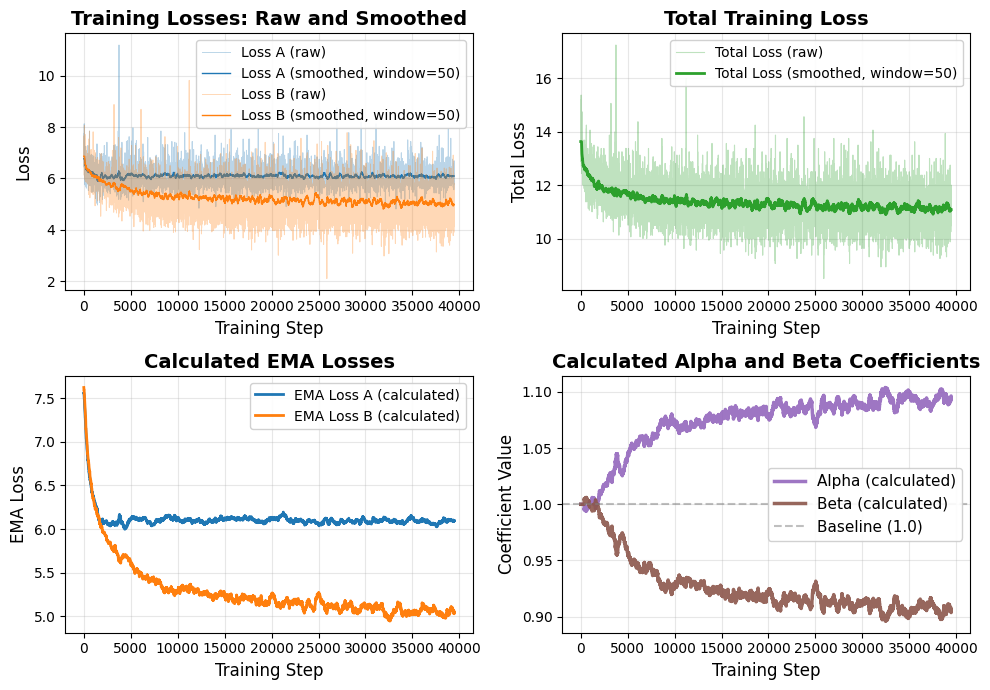

In [7]:
# Visualize losses for the case study run
if case_study_run.exists() and 'train/loss_A' in case_data:
    fig, axes = plt.subplots(2, 2, figsize=(10, 7))
    
    steps = case_data['train/loss_A']['steps']
    loss_A = case_data['train/loss_A']['values']
    loss_B = case_data['train/loss_B']['values']
    loss_total = case_data['train/loss_total']['values']
    
    # Smooth the losses
    smoothed_A = smooth_values(loss_A, window=smoothing_window)
    smoothed_B = smooth_values(loss_B, window=smoothing_window)
    smoothed_total = smooth_values(loss_total, window=smoothing_window)
    
    # Plot 1: Raw and smoothed losses (top-left)
    ax1 = axes[0, 0]
    ax1.plot(steps, loss_A, color=color_A, alpha=0.3, linewidth=0.7, label='Loss A (raw)')
    ax1.plot(steps, smoothed_A, color=color_A, alpha=1.0, linewidth=1.0, label=f'Loss A (smoothed, window={smoothing_window})')
    ax1.plot(steps, loss_B, color=color_B, alpha=0.3, linewidth=0.7, label='Loss B (raw)')
    ax1.plot(steps, smoothed_B, color=color_B, alpha=1.0, linewidth=1.0, label=f'Loss B (smoothed, window={smoothing_window})')
    
    ax1.set_xlabel('Training Step', fontsize=12)
    ax1.set_ylabel('Loss', fontsize=12)
    ax1.set_title('Training Losses: Raw and Smoothed', fontsize=14, fontweight='bold')
    ax1.legend(loc='best', framealpha=0.9)
    ax1.grid(True, alpha=0.3)
    
    # Plot 2: Total loss (top-right)
    ax2 = axes[0, 1]
    ax2.plot(steps, loss_total, color=color_total, alpha=0.3, linewidth=0.8, label='Total Loss (raw)')
    ax2.plot(steps, smoothed_total, color=color_total, alpha=1.0, linewidth=2.0, label=f'Total Loss (smoothed, window={smoothing_window})')
    
    ax2.set_xlabel('Training Step', fontsize=12)
    ax2.set_ylabel('Total Loss', fontsize=12)
    ax2.set_title('Total Training Loss', fontsize=14, fontweight='bold')
    ax2.legend(loc='best', framealpha=0.9)
    ax2.grid(True, alpha=0.3)
    
    # Plot 3: Calculated EMA losses (bottom-left)
    ax3 = axes[1, 0]
    ax3.plot(steps, coeffs['ema_loss_A'], color=color_A, linewidth=2.0, label='EMA Loss A (calculated)')
    ax3.plot(steps, coeffs['ema_loss_B'], color=color_B, linewidth=2.0, label='EMA Loss B (calculated)')
    
    ax3.set_xlabel('Training Step', fontsize=12)
    ax3.set_ylabel('EMA Loss', fontsize=12)
    ax3.set_title('Calculated EMA Losses', fontsize=14, fontweight='bold')
    ax3.legend(loc='best', framealpha=0.9)
    ax3.grid(True, alpha=0.3)
    
    # Plot 4: Calculated alpha and beta coefficients (bottom-right)
    ax4 = axes[1, 1]
    ax4.plot(steps, coeffs['alpha'], color=color_alpha, linewidth=2.5, label='Alpha (calculated)', alpha=0.9)
    ax4.plot(steps, coeffs['beta'], color=color_beta, linewidth=2.5, label='Beta (calculated)', alpha=0.9)
    ax4.axhline(y=1.0, color='gray', linestyle='--', linewidth=1.5, alpha=0.5, label='Baseline (1.0)')
    
    ax4.set_xlabel('Training Step', fontsize=12)
    ax4.set_ylabel('Coefficient Value', fontsize=12)
    ax4.set_title('Calculated Alpha and Beta Coefficients', fontsize=14, fontweight='bold')
    ax4.legend(loc='best', framealpha=0.9, fontsize=11)
    ax4.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()


## Comparison: Total Loss (Latest Run vs Case Study)


Latest run final loss: 11.332500
Case study final loss: 11.080000
Difference: 0.252500


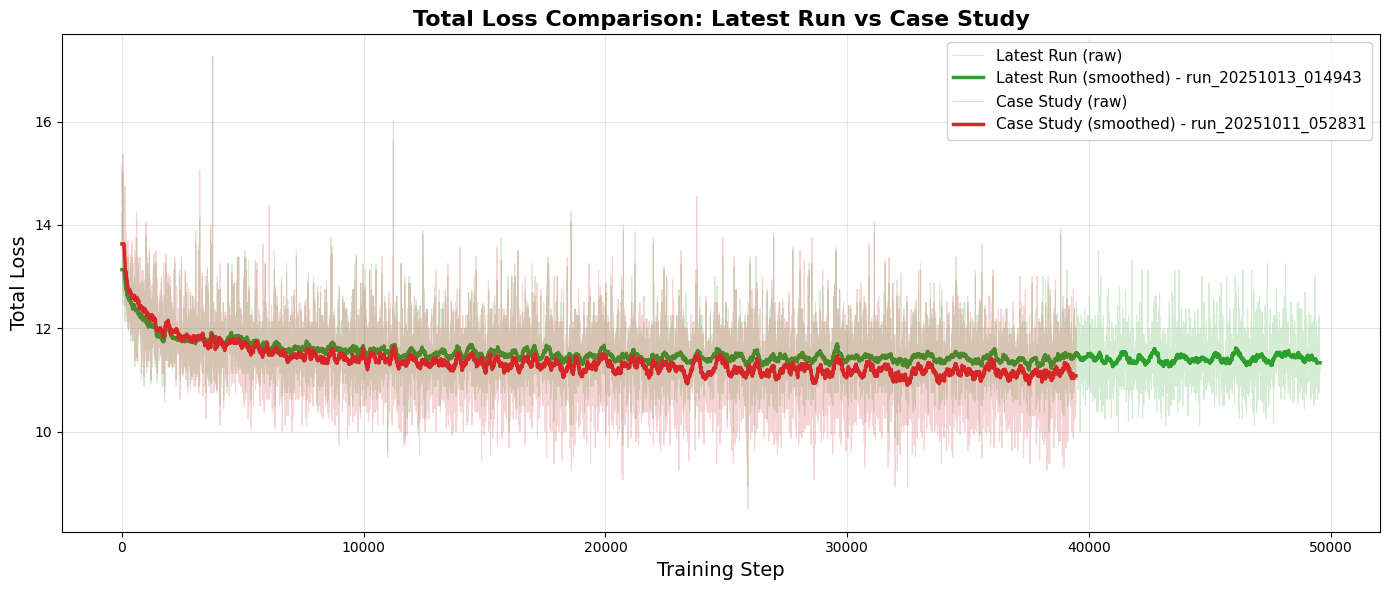

In [8]:
# Compare total loss between latest run and case study run
if 'train/loss_total' in data and case_study_run.exists() and 'train/loss_total' in case_data:
    fig, ax = plt.subplots(figsize=(14, 6))
    
    # Latest run (with alpha/beta)
    steps_latest = data['train/loss_total']['steps']
    loss_latest = data['train/loss_total']['values']
    smoothed_latest = smooth_values(loss_latest, window=smoothing_window)
    
    # Case study run (before alpha/beta)
    steps_case = case_data['train/loss_total']['steps']
    loss_case = case_data['train/loss_total']['values']
    smoothed_case = smooth_values(loss_case, window=smoothing_window)
    
    # Plot latest run
    ax.plot(steps_latest, loss_latest, color='#2ca02c', alpha=0.2, linewidth=0.8, label='Latest Run (raw)')
    ax.plot(steps_latest, smoothed_latest, color='#2ca02c', alpha=1.0, linewidth=2.5, 
            label=f'Latest Run (smoothed) - {latest_run.name}')
    
    # Plot case study run
    ax.plot(steps_case, loss_case, color='#d62728', alpha=0.2, linewidth=0.8, label='Case Study (raw)')
    ax.plot(steps_case, smoothed_case, color='#d62728', alpha=1.0, linewidth=2.5, 
            label=f'Case Study (smoothed) - {case_study_run.name}')
    
    ax.set_xlabel('Training Step', fontsize=14)
    ax.set_ylabel('Total Loss', fontsize=14)
    ax.set_title('Total Loss Comparison: Latest Run vs Case Study', fontsize=16, fontweight='bold')
    ax.legend(loc='best', framealpha=0.9, fontsize=11)
    ax.grid(True, alpha=0.3)
    
    # Print final loss values
    print(f"Latest run final loss: {smoothed_latest[-1]:.6f}")
    print(f"Case study final loss: {smoothed_case[-1]:.6f}")
    print(f"Difference: {smoothed_latest[-1] - smoothed_case[-1]:.6f}")
    
    plt.tight_layout()
    plt.show()
else:
    print("Warning: Could not compare - missing data")
